<a href="https://colab.research.google.com/github/hhcgoodluck/CSC412-Probabilistic-Learning-and-Reasoning/blob/main/CSC412_2026_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probabilistic ML: Assignment 2
- **Deadline**: 11:59PM October 19th
- **Submission**: You need to submit your solutions through Crowdmark, including all your derivations, plots, and your code. Please submit this notebook as a single PDF file. Points will be deducted if we have a hard time reading your solutions or understanding the structure of your code.
- **Collaboration policy**: After attempting the problems on an individual basis, you may discuss and work together on the assignment with up to two classmates. However, **you must write your own code and write up your own solutions individually and explicitly name any collaborators** at the top of the homework.

# Q1 - Image Denoising

In this problem, we will implement the sum-product Loopy **belief propagation** (Loopy-BP) method for denoising binary images which you have seen in tutorial 4.
We will consider images as matrices of size $\sqrt{n} \times \sqrt{n}$. Each element of the matrix can be either $1$ or $-1$, with $1$ representing white pixels and $-1$ representing black pixels. This is different from the $0/1$ representation commonly used for other CV tasks. This notation will be more convenient when multiplying with pixel values.

### Data preparation
Below we provide you with code for loading and preparing the image data.

First, we load a black and white image of Laika and convert it into a binary matrix of 1 and -1. So that white pixels have value 1 and black pixels have value -1.

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=291d2b00b9b511213e381473ba5711bca82d9403e57c7335ea1243e12b578960
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


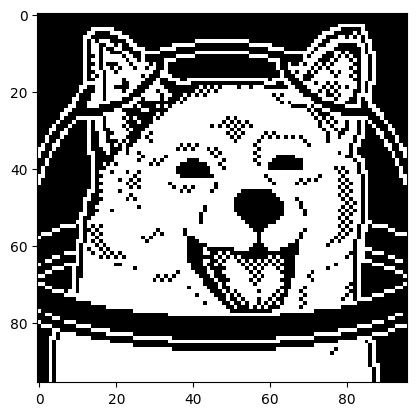

In [1]:
!pip install wget

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import PIL.Image as Image
from os.path import exists
from wget import download
from tqdm import tqdm
filename, url = "3vaef0cog4f61.png", "https://i.redd.it/3vaef0cog4f61.png"

def load_img():
    if not exists(filename):
        download(url)

    with open(filename, 'rb') as fp:
        img2 = Image.open(fp).convert('L')
        img2 = np.array(img2)
    return (img2[:96,11:107] > 120) * 2.0 - 1

img_true = load_img()
plt.imshow(img_true, cmap='gray')

To introduce noise into the image, for each pixel, swap its value between 1 and -1 with rate 0.2.


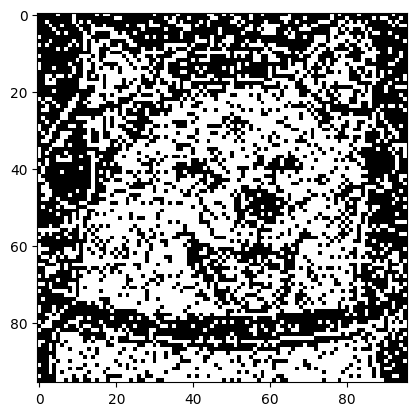

In [2]:
def gen_noisyimg(img, noise=.05):
    """
    Flip each pixel independently with probability `noise`.
    """
    flip = np.random.binomial(1, noise, size=img.shape)
    return img * (1 - 2 * flip)

noise = 0.2
img_noisy = gen_noisyimg(img_true, noise)
plt.imshow(img_noisy, cmap='gray')

### The Loopy BP algorithm


Recall from lecture and tutorial, the Loopy-BP algorithm iteratively updates the messages of each node through a sum-product operation. The **sum-product** operation computes the joint inbound message through multiplication, and then marginalizes the factors through summation. This is in contrast to the **max-product** BP, which computes the maximum a-posteriori value for each variable through taking the maximum over variables. Let $x_j\in\{-1,+1\}$ denote the unknown true value of pixel $j$, and let $y_j\in\{-1,+1\}$ denote its observed noisy value. The goal is to infer the values of $x_j$ from the noisy observations $y_j$.

Initialization:

For discrete node $x_j$ with $2$ possible states, $m_{i \rightarrow j}$ can be written as a $2$ dimensional real vector $\mathrm{m}_{i,j}$ with $m_{i \rightarrow j}(x_j) =  \mathrm{m}_{i,j}[index(x_j)]$. We initialize them uniformly to $m_{i \rightarrow j}(x_j) = 1/2$.

(Aside: for continuous cases, $m_{i \rightarrow j}(x_j)$ is a real valued function of $x_j$. We only need to deal with the discrete case here.)

For a number of iterations:

&nbsp;&nbsp;&nbsp;&nbsp;For node $x_j$ in $\{x_s\}_{s=1}^n$:  
1. Compute the product of inbound messages from neighbours of $x_j$:
$$\prod_{k \in N(j) \not = i} m_{k \rightarrow j}(x_j)$$

2. Compute potentials $\psi_j(x_j) = \exp (\beta x_j y_j)$ and $\psi_{ij}(x_i,x_j) = \exp(J_{ij} x_i x_j)$. This expression specifically holds when $x \in \{-1,+1\}$.

3. Marginalize over $x_j = \{-1, +1\}$ to get $m_{j \rightarrow i}(x_i)$:
$$
m_{j \rightarrow i}(x_i) = \sum_{x_j}\psi_j(x_j)\psi_{ij}(x_i, x_j)\prod_{k \in N(j) \not = i} m_{k \rightarrow j}(x_j)
$$
4. Normalize messages for stability $m_{j \rightarrow i}(x_i) =m_{j \rightarrow i}(x_i)/\sum_{x_i}m_{j \rightarrow i}(x_i)$.

Compute beliefs after message passing is done.
$$
b(x_i) \propto \psi_i(x_i) \prod_{j \in \mathcal N(i)} m_{j \rightarrow i}(x_i).
$$


You'll be tasked to perform steps 1-3 in the iterations and computing the beliefs. We will provide you with helper functions for initialization, finding neighbours, and normalization.

### Initialization
Initialize the message between neighbor pixels uniformly as $m_{j→i}(x_i) = 1/k$. Since each pixel can only be 1 or -1, message has two values $m_{j→i}(1)$ and $m_{j→i}(-1)$. We also initialize hyperparameters `J_horizontal`, `J_vertical` (the coupling strengths for horizontal and vertical edges, respectively), and $\beta$.

In [3]:
y = img_noisy.reshape([img_true.size, ])
num_nodes = len(y)
init_message = np.zeros([2, num_nodes, num_nodes]) + .5

# Horizontal edges have coupling J_horizontal.
# Vertical edges have coupling J_vertical.
J_horizontal = 1.0
J_vertical = 1.2

beta = 1.0

Find the neighboring pixels around a given pixel, which will be used for BP updates

In [4]:
def get_neighbors_of(node):
    """
    arguments:
     int node:  in [0,num_nodes) index of node to query
    globals:
     int num_nodes: number of nodes
    return: set(int) indices of neighbors of queried node
    """
    neighbors = []
    m = int(np.sqrt(num_nodes))
    if (node + 1) % m != 0:
        neighbors += [node + 1]
    if node % m != 0:
        neighbors += [node - 1]
    if node + m < num_nodes:
        neighbors += [node + m]
    if node - m >= 0:
        neighbors += [node - m]

    return set(neighbors)

In [5]:
def get_edge_coupling(node1, node2):
    """
    Return the pairwise coupling J_ij for two neighboring pixels i and j.

    Horizontal edges have coupling J_horizontal.
    Vertical edges have coupling J_vertical.
    """
    m = int(np.sqrt(num_nodes))

    row1, col1 = divmod(node1, m)
    row2, col2 = divmod(node2, m)

    if row1 == row2 and abs(col1 - col2) == 1:
        return J_horizontal

    if col1 == col2 and abs(row1 - row2) == 1:
        return J_vertical

    raise ValueError("node1 and node2 must be neighboring pixels")

## Q1.1 Implement message passing in BP (20 points)


Implement the function `get_message()` that computes the message passed from node j to node i: $$
m_{j \rightarrow i}(x_i) = \sum_{x_j}\psi_j(x_j)\psi_{ij}(x_i, x_j)\prod_{k \in N(j) \not = i} m_{k \rightarrow j}(x_j)
$$
`get_message()` will be used by (provided below) `step_bp()` to perform one iteration of loopy-BP: it first normalizes the returned message from `get_message()`, and then updates the message with momentum `1.0 - step`.

Note: since horizontal and vertical edges use different coupling strength, you should make use of `get_edge_coupling`.

In [6]:
def get_message(node_from, node_to, messages):
    """
    arguments:
     int node_from: in [0,num_nodes), source node
     int node_to: in [0,num_nodes), target node
     float array messages: (2,num_nodes,num_nodes), messages[:,j,i]
                           is the message from node j to node i.
                           Entry 0 corresponds to x_i=+1 and entry 1
                           corresponds to x_i=-1.
    reads globals:
     float array y: (num_nodes,), observed pixel values
     float beta: observation-to-true-pixel coupling strength
    returns:
     float array: (2,), unnormalized message from node_from to node_to
    """
    # [Done] implement your function here
    states = np.array([1, -1])

    # Product of incoming messages, excluding the target node.
    incoming = np.ones(2)
    for neighbor in get_neighbors_of(node_from) - {node_to}:
        incoming *= messages[:, neighbor, node_from]

    # Unary potential at the source node.
    unary = np.exp(beta * states * y[node_from])

    # Pairwise potential: rows are target states, columns are source states.
    J_ij = get_edge_coupling(node_from, node_to)
    pairwise = np.exp(J_ij * np.outer(states, states))

    # Sum over the two possible source states.
    return pairwise @ (unary * incoming)


def step_bp(step, messages):
    """
    arguments:
     float step: step size to update messages
    return
     float array messages: (2, num_nodes, num_nodes), messages[:,j,i] is message
                           from node j to node i
    """
    for node_from in range(num_nodes):
        for node_to in get_neighbors_of(node_from):
            m_new = get_message(node_from, node_to, messages)
            # normalize
            m_new = m_new / np.sum(m_new)

            messages[:, node_from, node_to] = step * m_new + (1. - step) * \
                messages[:, node_from, node_to]
    return messages

Then, run loopy BP update for 10 iterations:

In [7]:
num_iter = 10
step = 0.5
for it in range(num_iter):
    init_message = step_bp(step, init_message)
    print(it + 1,'/',num_iter)

1 / 10
2 / 10
3 / 10
4 / 10
5 / 10
6 / 10
7 / 10
8 / 10
9 / 10
10 / 10


## Q1.2 Computing belief from messages (10 points)


Now, calculate the unnormalized belief for each pixel
$$ \tilde{b}(x_i) = \psi_i(x_i) ∏_{j \in N(i)}m_{j→i}(x_i),$$
and normalize over the two possible states of pixel $i$:
$$b_i(x_i) = \frac{\tilde b_i(x_i)}{\sum_{x_i'\in\{-1,+1\}}\tilde b_i(x_i')}.$$

In [53]:
def update_beliefs(messages):
    """
    arguments:
    float array messages: (2, num_nodes, num_nodes), messages[:,j,i] is message
                           from node j to node i
    reads globals:
     float beta: observation to true pixel coupling strength constant
     float array y: (num_nodes,) observed pixel values
    returns:
     float array beliefs: (2, num_nodes), beliefs[:,i] is the belief of node i
    """
    beliefs = np.zeros([2, num_nodes])
    for node in range(num_nodes):
        # [Done] implement belief calculation here

        # Unary potential, with state order [+1, -1].
        # states = np.array([1, -1])
        belief = np.exp(beta * np.array([1, -1]) * y[node])

        # Multiply all incoming messages.
        for neighbor in get_neighbors_of(node):
            belief *= messages[:, neighbor, node]

        # Normalize over the two states.
        beliefs[:, node] = belief / np.sum(belief)
    return beliefs

# Call update_beliefs() once
beliefs = update_beliefs(init_message)

Finally, to get the denoised image, we use 0.5 as the threshold and consider pixel with belief less than threshold as black while others as white.

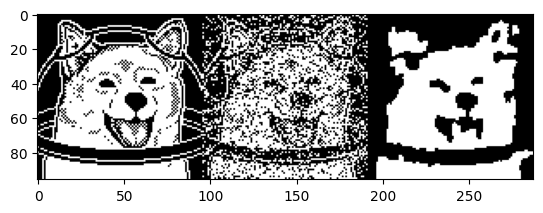

In [9]:
pred = np.where(beliefs[0, :] >= beliefs[1, :],+1.,-1.)

img_out = pred.reshape(img_true.shape)

plt.imshow(np.hstack([img_true, img_noisy, img_out]), cmap='gray')

## Question 1.3 Momentum in belief propagation
In the sample code provided above, we performed message update using step size `step`, with momentum `1.0 - step` on the previous message. In this question, you will experimentally investigate how momentum affects the characteristics of convergence.




### Question 1.3.1 (5 points)
Complete the function `test_trajectory` below to obtain predicted image after each step of message passing. Return predicted images as list.

In [10]:
def test_trajectory(step_size, max_step=10):
    """
    step_size: step_size to update messages in each iteration
    max_step: number of steps
    """
    # re-initialize each time
    messages = np.zeros([2, num_nodes, num_nodes]) + .5
    images = []

    # [Done]
    for _ in range(max_step):
        messages = step_bp(step_size, messages)
        beliefs = update_beliefs(messages)
        pred = np.where(beliefs[0, :] >= beliefs[1, :], +1., -1.)
        images.append(pred.reshape(img_true.shape))

    return images

### Question 1.3.2 (5 points)
Use test trajectory to create image serieses for `step size` 0.1, 0.3, and 1.0, each with 10 steps. Display these images with `plot_series' provided below.

In the textbox below, 1. comment on what happens when a large step size is used for too many iterations. 2. how would you adjust other hyperparameters to counteract this effect?

step_size = 0.1
step_size = 0.3
step_size = 1.0


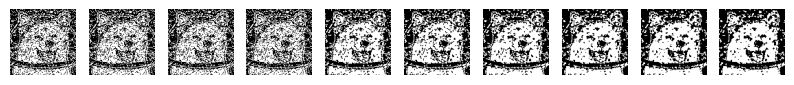

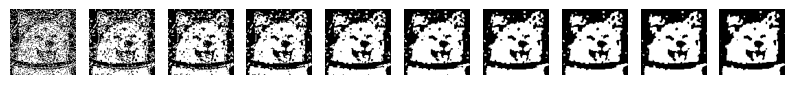

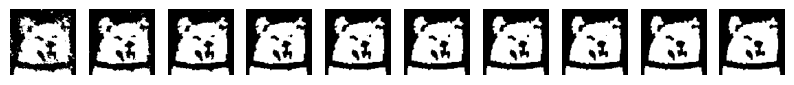

In [12]:
def plot_series(images):

  n = len(images)
  fig, ax = plt.subplots(1, n)
  for i in range(n):
    ax[i].imshow(images[i], cmap='gray')
    ax[i].set_axis_off()
  fig.set_figwidth(10)
  fig.show()

# [Done]
for step_size in [0.1, 0.3, 1.0]:
    print("step_size =", step_size)
    images = test_trajectory(step_size, max_step=10)
    plot_series(images)



### Response to 1.3.2 (Enter your response below):

1. A large step size removes noise quickly, but too many iterations cause over-smoothing and loss of fine details.

2. To counteract this, decrease J_horizontal and J_vertical or increase beta to give more weight to the observations.


## Question 1.4 Effect of noise level and coupling strength
Let $c > 0$. In this question, we will set `J_horizontal` to be $c$ and `J_vertical` to be $1.2c$ and study how the level of noise in the image influences our choice of $c$.

### Question 1.4.1 (5 points)
First, generate and display images with noise of $0.05$, $0.3$.
In the text box below, comment on what would happen if noise was set to $0.5$ and $1.0$

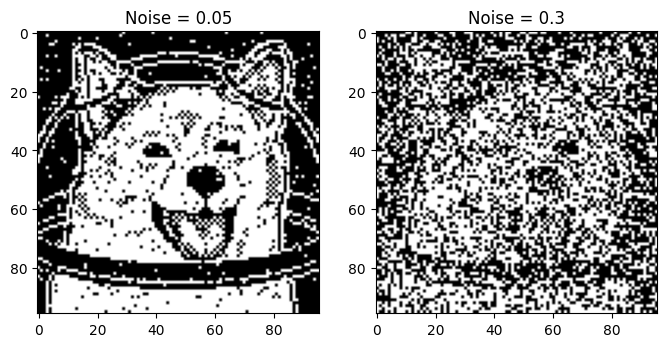

In [51]:
# [Done]
noise_levels = [0.05, 0.3]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, noise in zip(axes, noise_levels):
    noisy_img = gen_noisyimg(img_true, noise)
    ax.imshow(noisy_img, cmap='gray')
    ax.set_title(f"Noise = {noise}")

plt.show()

### Response to 1.4.1 (enter your response below):

1. At noise 0.5, each pixel is equally likely to be +1 or -1, independently of its true value. The result is random black-and-white noise containing no information about the original image.

2. At noise 1.0, every pixel is flipped, producing an exact black-and-white inversion of the original image while preserving its shapes and features.


### Question 1.4.2 (5 points)


Now, perform image denoising on images with noise levels $0.05$ and $0.3$, and for each noise level, use $c=0.1$, $c=0.5$, $c=1.0$, and $c=5.0$. Horizontal edges should have coupling `J_horizontal` $ = c$ and vertical edges should have coupling `J_vertical` $=1.2c$. Set step size to 0.8 and max_step to 5. Plot the denoised images (if reusing `test_trajectory`, you should plot 8 image serieses).
In text box below, comment on what you observe and provide a brief explanation on why this might occur.

noise = 0.05, c = 0.1
noise = 0.05, c = 0.5
noise = 0.05, c = 1.0
noise = 0.05, c = 5.0
noise = 0.3, c = 0.1
noise = 0.3, c = 0.5
noise = 0.3, c = 1.0
noise = 0.3, c = 5.0


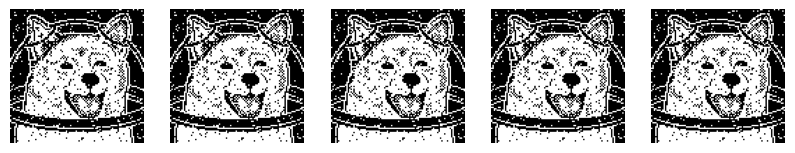

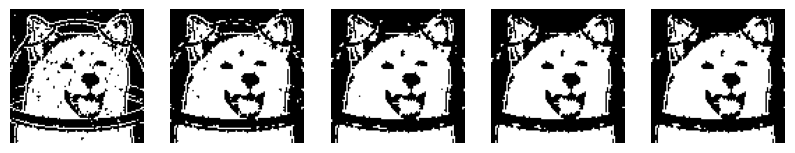

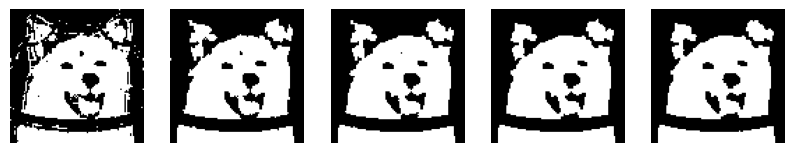

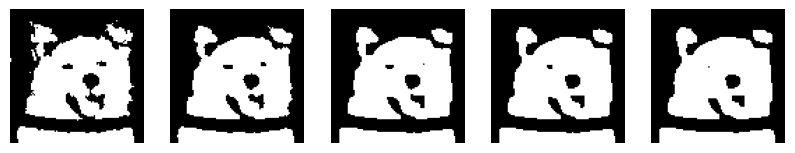

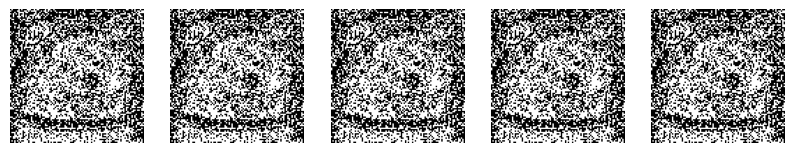

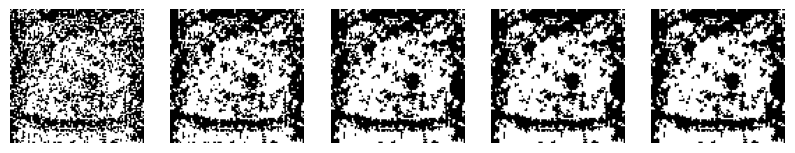

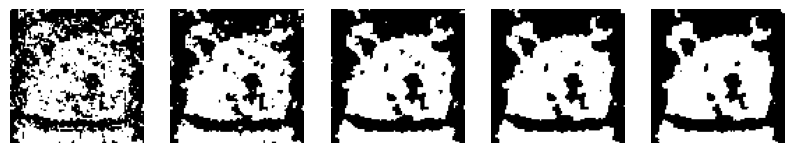

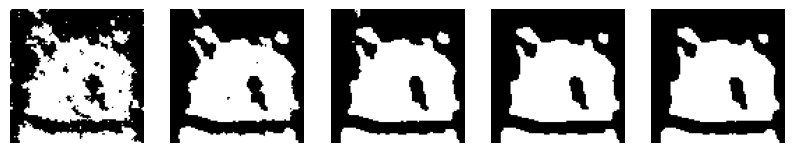

In [52]:
for noise in [0.05, 0.3]:
    img_noisy = gen_noisyimg(img_true, noise)
    y = img_noisy.reshape(-1)

    for c in [0.1, 0.5, 1.0, 5.0]:
        J_horizontal = c
        J_vertical = 1.2 * c

        print(f"noise = {noise}, c = {c}")
        images = test_trajectory(step_size=0.8, max_step=5)
        plot_series(images)

### Response to 1.4.2 (enter your response below):

1. At noise 0.05, c = 0.5 removes much of the noise while retaining recognizable details.

2. At noise 0.3, c = 1.0 removes more noise than c = 0.5, but some details are lost.

3. At both noise levels, c = 0.1 leaves noise largely unchanged, while c = 5.0 causes severe over-smoothing.

4. Larger c strengthens the preference for neighboring pixels to agree, removing noise but also erasing fine structures.

# Question 2: Markov chain Monte Carlo in the TrueSkill model

The goal of this question is to get you familiar with the basics of
Bayesian inference in medium-sized models with continuous latent variables, and the basics of Hamiltonian Monte Carlo.

## Background

We'll implement a variant of the [TrueSkill](http://papers.nips.cc/paper/3079-trueskilltm-a-bayesian-skill-rating-system.pdf) model, a player ranking system for competitive games originally developed for Halo 2.
It is a generalization of the Elo rating system in Chess.

This assignment is based on [this one](https://mlg.eng.cam.ac.uk/teaching/4f13/2324/) developed by Carl Rasmussen at Cambridge for his course on probabilistic machine learning.

## Model definition
We'll consider a slightly simplified version of the original trueskill model.
We assume that each player has a true, but unknown skill $z_i \in \mathbb{R}$.
We use $N$ to denote the number of players.

### The prior:
We will assume that the prior over each player's skill is a Gaussian distribution,

$$z_i \sim \mathcal N(0,\sigma_z^2)$$
where $\sigma_z=1.5$ and players' skills are a priori independent.

### The likelihood:
For each observed game, the probability that player $i$ beats player $j$, given the player's skills $z_A$ and $z_B$, is:
$$p(A \,\, \text{beat} \,\, B | z_A, z_B) = \sigma(z_A - z_B)$$
where
$$\sigma(y) = \frac{1}{1 + \exp(-y)}$$
We chose this function simply because it's close to zero or one when the player's skills are very different, and equals one-half when the player skills are the same.  This likelihood function is the only thing that gives meaning to the latent skill variables $z_1 \dots z_N$.

There can be more than one game played between a pair of players. The outcome of each game is independent given the players' skills.
We use $M$ to denote the number of games.


In [15]:
!pip install wget
import os
import os.path

import matplotlib.pyplot as plt
import wget

import pandas as pd


import numpy as np
from scipy.stats import norm
import scipy.io
import scipy.stats
import torch
import random
from torch.distributions.normal import Normal

from functools import partial

import matplotlib.pyplot as plt

In [54]:
# Standard deviation of the prior over player skills
prior_std = 1.5

## Q 2.1 Implementing the TrueSkill Model [10 points]

###	Q 2.1.a [4 points]
Implement a function $\texttt{log_joint_prior}$ that computes the log of the prior, jointly evaluated over all player's skills.

  Specifically, given a $K \times N$ array where each row is a setting of the skills for all $N$ players, it returns a length-$K$ array, where each row contains a scalar giving the log-prior for that set of skills.

In [55]:
def log_joint_prior(zs_array):
    # [Done]
    return torch.distributions.Normal(0, prior_std).log_prob(zs_array).sum(dim=-1)

### Q 2.1.b [6 points]

Implement two functions $\texttt{logp_a_beats_b}$ and $\texttt{logp_b_beats_a}$.

Given a pair of skills $z_a$ and $z_b$, $\texttt{logp_a_beats_b}$ evaluates the log-likelihood that player with skill $z_a$ beat player with skill $z_b$ under the model detailed above, and $\texttt{logp_b_beats_a}$ is vice versa.

To ensure numerical stability, use the function $torch.logaddexp$


In [20]:
def logp_a_beats_b(z_a, z_b):
    # Hint: Use torch.logaddexp
    # [Done]
    diff = z_b - z_a
    return -torch.logaddexp(torch.zeros_like(diff), diff)

def logp_b_beats_a(z_a, z_b):
    # Hint: Use torch.logaddexp
    # [Done]
    diff = z_a - z_b
    return -torch.logaddexp(torch.zeros_like(diff), diff)

## Q 2.2 Examining the posterior for only two players and toy data [10 points]
To get a feel for this model, we'll first consider the case where we only have 2 players, $A$ and $B$.
We'll examine how the prior and likelihood interact when conditioning on different sets of games.

Provided in the starter code is a function $\texttt{plot_isocontours}$ which evaluates a provided function on a grid of $z_A$ and $z_B$'s and plots the isocontours of that function.
There is also a function $\texttt{plot_2d_fun}$.
We have included an example for how you can use these functions.



In [56]:
# Plotting helper functions
def plot_isocontours(ax, func, steps=100):
    x = torch.linspace(-4, 4, steps=steps)
    y = torch.linspace(-4, 4, steps=steps)
    X, Y = torch.meshgrid(x, y, indexing="ij")
    Z = func(X, Y)
    cs = plt.contour(X, Y, Z )
    plt.clabel(cs, inline=1, fontsize=10)
    ax.set_yticks([])
    ax.set_xticks([])

def plot_2d_fun(f, x_axis_label="", y_axis_label="", scatter_pts=None):
    # This is the function your code should call.
    # f() should take two arguments.
    fig = plt.figure(figsize=(8,8), facecolor='white')
    ax = fig.add_subplot(111, frameon=False)
    ax.set_xlabel(x_axis_label)
    ax.set_ylabel(y_axis_label)
    plot_isocontours(ax, f)
    if scatter_pts is not None:
      plt.scatter(scatter_pts[:,0], scatter_pts[:, 1])
    plt.plot([4, -4], [4, -4], 'b--')   # Line of equal skill
    plt.show(block=True)
    plt.draw()


### Q 2.2.a [2 point]
For two players $A$ and $B$, plot the isocontours of the joint prior over their skills.  Also plot the line of equal skill, $z_A = z_B$. Use the helper function `plot_2d_fun` above to plot.

According to the prior, what's the chance that player A is better than player B?

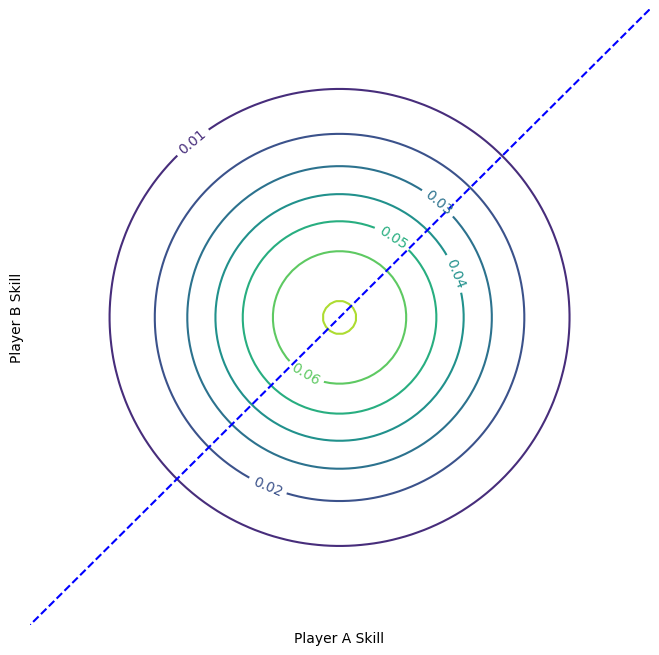

<Figure size 640x480 with 0 Axes>

In [57]:
def log_prior_over_2_players(z1, z2):
    # [Done]
    return log_joint_prior(torch.stack((z1, z2), dim=-1))

def prior_over_2_players(z1, z2):
    return torch.exp(log_prior_over_2_players(z1, z2))

plot_2d_fun(prior_over_2_players, "Player A Skill", "Player B Skill")

The probability is 0.5 because the players have identical independent continuous priors, so P(z_A > z_B) = P(z_B > z_A), and ties have probability zero.

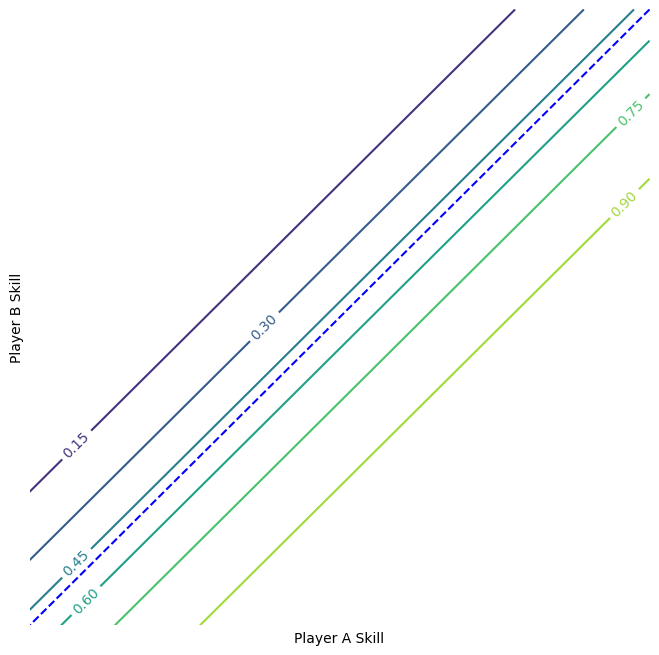

<Figure size 640x480 with 0 Axes>

In [23]:
# Note:  This isn't part of TODO
def likelihood_over_2_players(z1, z2):
    return torch.exp(logp_a_beats_b(z1, z2))

plot_2d_fun(likelihood_over_2_players, "Player A Skill", "Player B Skill")

### Q 2.2.b [3 points]

Plot isocountours of the joint posterior over $z_A$ and $z_B$ given that player A
beat player B in one match.  Since the contours don't depend on the normalization
constant, you can simply plot the isocontours of the log of joint distribution of
$p(z_A, z_B | \text{A beat B})$. Also plot the line of equal skill, $z_A = z_B$.

To think about: According to this posterior, which player is likely to have higher skill?

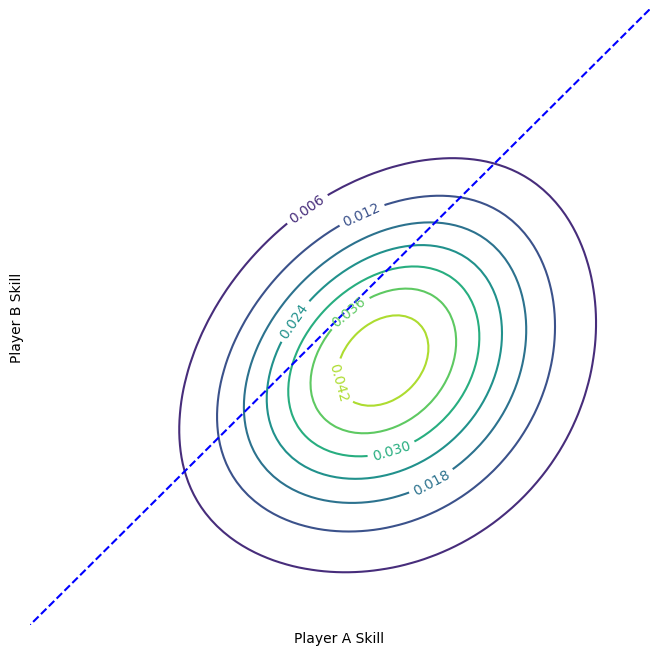

<Figure size 640x480 with 0 Axes>

In [25]:
def log_posterior_A_beat_B(z1, z2):
    # [Done] Combine the prior for two players with the likelihood for A beat B.
    # You might want to use the log_prior_over_2_players function from above.
    return log_prior_over_2_players(z1, z2) + logp_a_beats_b(z1, z2)

def posterior_A_beat_B(z1, z2):
    return torch.exp(log_posterior_A_beat_B(z1, z2))

plot_2d_fun(posterior_A_beat_B, "Player A Skill", "Player B Skill")
# Note that the posterior probabilities shown are unnormalized

Player A is more likely to have higher skill, since the posterior favors z_A > z_B after A wins one match.

### Q 2.2.c [2 point]

Plot isocountours of the joint posterior over $z_A$ and $z_B$ given that
4 matches were played, and player A beat player B in all 4 matches.
Also plot the line of equal skill, $z_A = z_B$.

To think about: According to this posterior, is it plausible that player B is more skilled than player A?

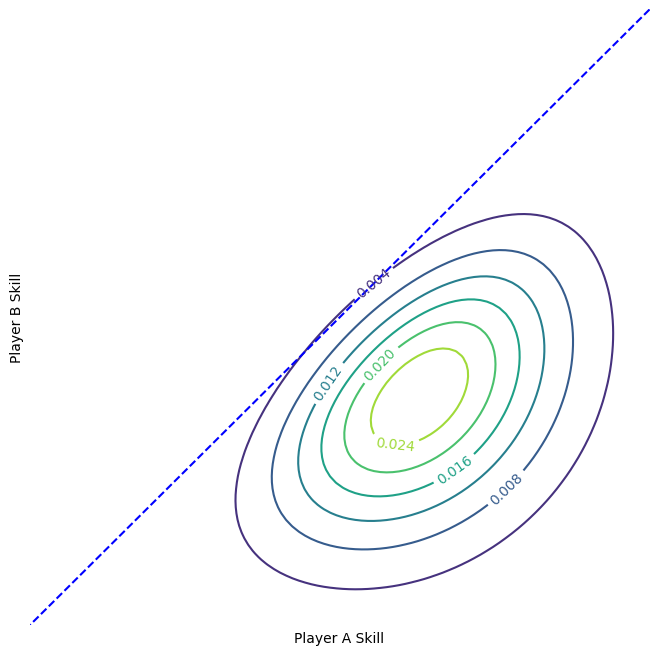

<Figure size 640x480 with 0 Axes>

In [26]:
def log_posterior_A_beat_B_4_times(z1, z2):
    # [Done] Combine the prior for two players with the likelihood for A beat B.
    # You might want to use your log_prior_over_2_players function.
    return log_prior_over_2_players(z1, z2) + 4 * logp_a_beats_b(z1, z2)

def posterior_A_beat_B_4_times(z1, z2):
    return torch.exp(log_posterior_A_beat_B_4_times(z1, z2))

plot_2d_fun(posterior_A_beat_B_4_times, "Player A Skill", "Player B Skill")

It is still possible that B is more skilled than A, but it is unlikely after A wins all four matches.

### Q 2.2.d [3 point]

Plot isocontours of the joint posterior over $z_A$ and $z_B$ given that
8 matches were played, and each player beat the other 4 times.
Also plot the line of equal skill, $z_A = z_B$.

To think about: According to this posterior, is it likely that one player is much better than another?  Is it plausible that both players are better than average?  Worse than average?

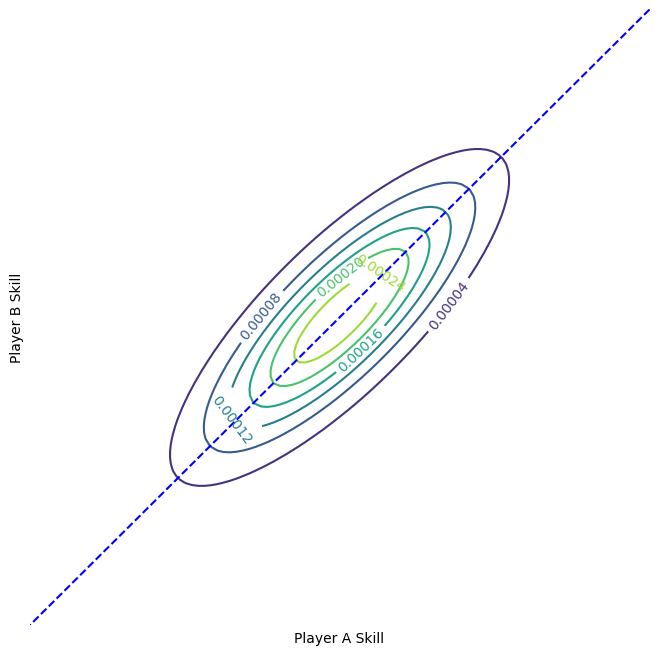

<Figure size 640x480 with 0 Axes>

In [58]:
def log_posterior_beat_each_other_4_times(z1, z2):
    # [Done] Combine the prior for two players with the likelihood for A beat B.
    # You might want to use your log_prior_over_2_players function from above.
    return (
        log_prior_over_2_players(z1, z2)
        + 4 * logp_a_beats_b(z1, z2)
        + 4 * logp_b_beats_a(z1, z2)
    )

def posterior_beat_each_other_4_times(z1, z2):
    return torch.exp(log_posterior_beat_each_other_4_times(z1, z2))

plot_2d_fun(posterior_beat_each_other_4_times, "Player A Skill", "Player B Skill")

Neither player is likely to be much better than the other, since each won four matches.
Both could plausibly be above average or below average, because their matches reveal relative skill rather than their shared absolute skill level.

## Q 2.3 Hamiltonian Monte Carlo on Two Players and Toy Data [4 points]

One nice thing about a Bayesian approach is that it separates the model specification from the approximate inference strategy.
The original Trueskill paper from 2007 used message passing.
Carl Rasmussen's assignment uses Gibbs sampling.

In this question, we will approximate posterior distributions with gradient-based Hamiltonian Monte Carlo.

In the next assignment, we'll use gradient-based stochastic variational inference, which wasn't invented until around 2014.


In [28]:
random.seed(42)
torch.manual_seed(42)

In [29]:
# Hamiltonian Monte Carlo
from tqdm import trange, tqdm_notebook  # Progress meters

def leapfrog(params_t0, momentum_t0, stepsize, logprob_grad_fun):
  # Performs a reversible update of parameters and momentum
  # See https://en.wikipedia.org/wiki/Leapfrog_integration
  momentum_thalf = momentum_t0    + 0.5 * stepsize * logprob_grad_fun(params_t0)
  params_t1 =      params_t0      +       stepsize * momentum_thalf
  momentum_t1 =    momentum_thalf + 0.5 * stepsize * logprob_grad_fun(params_t1)
  return params_t1, momentum_t1


def iterate_leapfrogs(theta, v, stepsize, num_leapfrog_steps, grad_fun):
  for i in range(0, num_leapfrog_steps):
    theta, v = leapfrog(theta, v, stepsize, grad_fun)
  return theta, v

def metropolis_hastings(state1, state2, log_posterior):
  # Compares the log_posterior at two values of parameters,
  # and accepts the new values proportional to the ratio of the posterior
  # probabilities.
  accept_prob = torch.exp(log_posterior(state2) - log_posterior(state1))
  if random.random() < accept_prob:
    return state2  # Accept
  else:
    return state1  # Reject

def draw_samples(num_params, stepsize, num_leapfrog_steps, n_samples, log_posterior):
  theta = torch.zeros(num_params)

  def log_joint_density_over_params_and_momentum(state):
    params, momentum = state
    m = Normal(0., 1.)
    return m.log_prob(momentum).sum(axis=-1) + log_posterior(params)

  def grad_fun(zs):
    zs = zs.detach().clone()
    zs.requires_grad_(True)
    y = log_posterior(zs)
    y.backward()
    return zs.grad

  sampleslist = []
  for i in trange(0, n_samples):
    sampleslist.append(theta)

    momentum = torch.normal(0, 1, size = np.shape(theta))

    theta_new, momentum_new = iterate_leapfrogs(theta, momentum, stepsize, num_leapfrog_steps, grad_fun)

    theta, momentum = metropolis_hastings((theta, momentum), (theta_new, momentum_new), log_joint_density_over_params_and_momentum)
  return torch.stack((sampleslist))

Using samples generated by HMC, we can approximate the joint posterior where we observe player A winning 1 game.

100%|██████████| 2500/2500 [00:40<00:00, 61.84it/s]


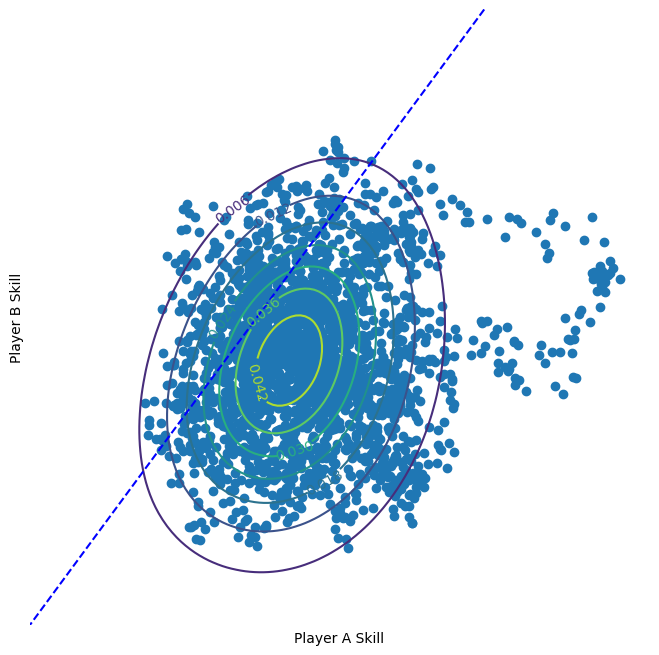

<Figure size 640x480 with 0 Axes>

In [30]:
# Hyperparameters
num_players = 2
num_leapfrog_steps = 20
n_samples = 2500
stepsize = 0.01

def log_posterior_a(zs):
  z1, z2 = zs[0], zs[1]
  return log_posterior_A_beat_B(z1, z2)

samples_a = draw_samples(num_players, stepsize, num_leapfrog_steps, n_samples, log_posterior_a)
plot_2d_fun(posterior_A_beat_B, "Player A Skill", "Player B Skill", samples_a)

### Q 2.3.a [2 point]

Using samples generated by HMC, approximate the joint posterior where we observe player A winning 4 games against player B.  Hint:  You can re-use the code from when you plotted the isocontours.

100%|██████████| 2500/2500 [00:58<00:00, 42.68it/s]


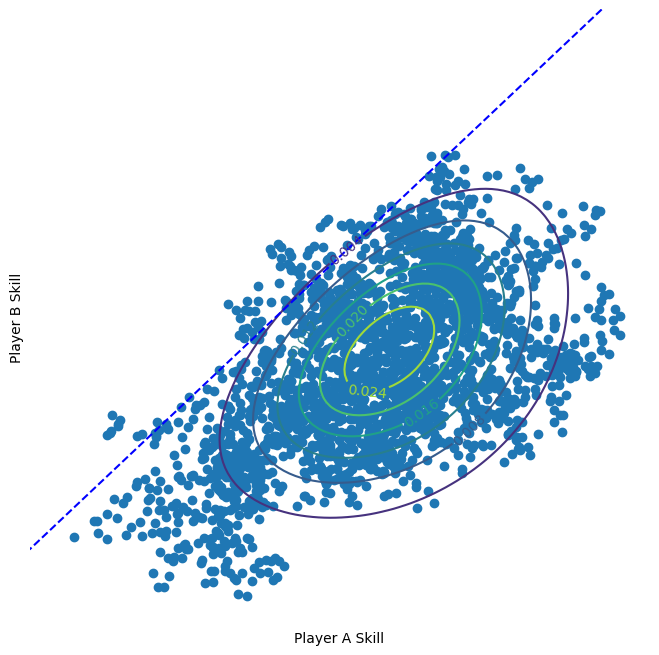

<Figure size 640x480 with 0 Axes>

In [60]:
# Hyperparameters
num_players = 2
num_leapfrog_steps = 20
n_samples = 2500
stepsize = 0.01

def log_posterior_b(zs):
    z1, z2 = zs[0], zs[1]
    return log_posterior_A_beat_B_4_times(z1, z2)

# Run HMC and plot the posterior contour and the samples
sample_b = draw_samples(num_players, stepsize, num_leapfrog_steps, n_samples, log_posterior_b)
plot_2d_fun(posterior_A_beat_B_4_times, "Player A Skill", "Player B Skill", sample_b)

### Q 2.3.b [2 point]

Using samples generated by HMC, approximate the joint posterior where we observe player A winning 4 games and player B winning 4 games.

100%|██████████| 2500/2500 [01:09<00:00, 36.05it/s]


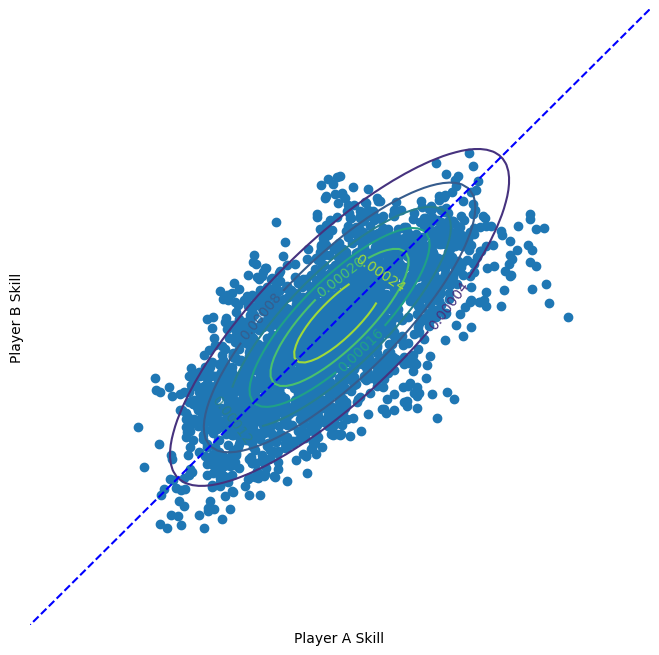

<Figure size 640x480 with 0 Axes>

In [63]:
# Hyperparameters
num_players = 2
num_leapfrog_steps = 20
n_samples = 2500
stepsize = 0.01


def log_posterior_c(zs):
    z1, z2 = zs[0], zs[1]
    return log_posterior_beat_each_other_4_times(z1, z2)

# Run HMC and plot the posterior contour and the samples
sample_c = draw_samples(num_players, stepsize, num_leapfrog_steps, n_samples, log_posterior_c)
plot_2d_fun(posterior_beat_each_other_4_times, "Player A Skill", "Player B Skill", sample_c)

## Q 2.4 Approximate inference conditioned on real data [26 points]

We will now apply the model to a collection of chess games.
`names[i]` contains the name of player $i$. Each row of games represents one observed game:

The first column contains the indices of the players who won.
The second column contains the indices of the player who lost.

It is based on the kaggle chess dataset: https://www.kaggle.com/datasets/datasnaek/chess




In [33]:
wget.download("https://vahidbalazadeh.me/assets/datasets/chess_players.csv")
wget.download("https://vahidbalazadeh.me/assets/datasets/chess_games.csv")
games = pd.read_csv("chess_games.csv")[["winner_id", "loser_id"]].to_numpy()
names = pd.read_csv("chess_players.csv")["player_name"].astype(str).to_numpy()

In [34]:
games = torch.LongTensor(games)

num_players = len(names)
num_games = len(games)

print(num_players, "players")
print(num_games, "games")

1163 players
2543 games


### Q 2.4.a [5 points]

Assuming all game outcomes are independent conditioned on all players' skills, implement a function $\texttt{log_games_likelihood}$ that takes a batch of player skills $\texttt{zs}$ and a collection of observed games $\texttt{games}$ and gives the total log-likelihoods for all those observations given all the skills.

Hint: You should be able to write this function without using $\texttt{for}$ loops, although you might want to start that way to make sure what you've written is correct.  If $A$ is an array of integers, you can index the corresponding entries of another matrix $B$ for every entry in $A$ by writing $\texttt{B[A]}$.

In [62]:
def log_games_likelihood(zs, games):
    # games is an array of size (num_games x 2)
    # zs is an array of size num_players
    # Hint: With broadcasting, this function can be written with no for loops.

    winning_player_ixs = games[:,0]
    losing_player_ixs = games[:,1]

    # Look up the skill of the winning player in each game.
    winning_player_skills = zs[winning_player_ixs]

    # Look up the skills of the losing player in each game.
    losing_player_skills = zs[losing_player_ixs]

    # Compute the log_likelihood of each game outcome.
    log_likelihoods = logp_a_beats_b(winning_player_skills, losing_player_skills)

    # Combine the log_likelihood of independent events.
    return log_likelihoods.sum()

  
### Q 2.4.b [3 points]
Implement a function $\texttt{log_joint_probability}$ which combines the log-prior and log-likelihood of the observations to give $\log p(z_1, z_2, \dots, z_N, \text{all game outcomes})$

In [64]:
def log_joint_probability(zs, games):
    # [Done] Combine log_prior and log_likelihood
    return log_joint_prior(zs) + log_games_likelihood(zs, games)

### Q 2.4.c [5 points]
Run Hamiltonian Monte Carlo on the posterior over all skills conditioned on all the chess games from the dataset.  Run for 10000 samples.

In [76]:
# Hyperparameters
num_players = 1163
num_leapfrog_steps = 20
n_samples = 10000
stepsize = 0.01

# Hint: you will need to use games
def log_posterior(zs):
    return log_joint_probability(zs, games)

all_games_samples = draw_samples(
    num_players,
    stepsize,
    num_leapfrog_steps,
    n_samples,
    log_posterior
)

100%|██████████| 10000/10000 [05:02<00:00, 33.11it/s]


### Q 2.4.d [3 points]
Based on your samples from the previous question, plot the approximate mean and standard deviaton of the marginal skill of each player, sorted by average skill. There's no need to include the names of the players.  Label the axes "Player Rank", and "Player Skill".

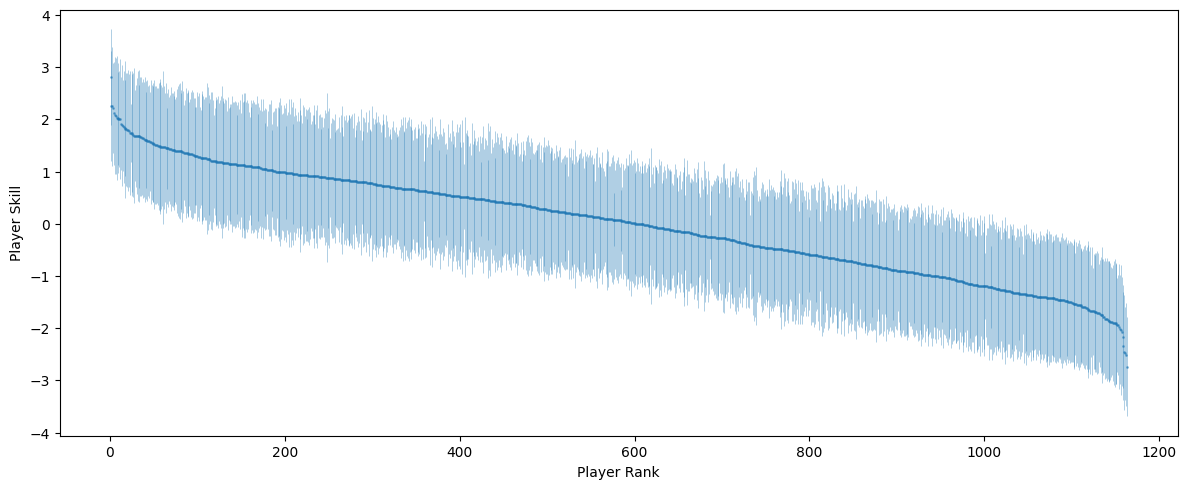

In [80]:
mean_skills = all_games_samples.mean(dim=0)

std_skills = all_games_samples.std(dim=0)

# Rank players from highest to lowest mean skill.
sorted_ixs = torch.argsort(mean_skills, descending=True)
ranks = np.arange(1, num_players + 1)

plt.figure(figsize=(12, 5))
plt.errorbar(
    ranks,
    mean_skills[sorted_ixs].detach().cpu().numpy(),
    yerr=std_skills[sorted_ixs].detach().cpu().numpy(),
    fmt='.',
    markersize=2,
    elinewidth=0.5,
    alpha=0.5
)
plt.xlabel("Player Rank")
plt.ylabel("Player Skill")
plt.tight_layout()
plt.show()

### Q 2.4.e [2 points]
List the names of the 5 players with the lowest mean skill and 5 players with the highest mean skill according to your samples.

In [39]:
print("Bottom 5")
# [Done] Print the 5 players with the lowest mean skill
bottom_ixs = torch.argsort(mean_skills)[:5]
for i in bottom_ixs.tolist():
    print(names[i])

print("Top 5")
# [Done] Print the 5 players with the highest mean skill
top_ixs = torch.argsort(mean_skills, descending=True)[:5]
for i in top_ixs.tolist():
    print(names[i])

Bottom 5
josephelbouhessaini
kylarr
vkmansftw
italiantranslator
mrmandelbrot
Top 5
doraemon61
mrzoom47
moistvonlipwig
lupanama
smartduckduckcow


### Q 2.4.f [2 points]
Use a scatterplot to show your samples over the joint posterior over the skills of italiantranslator and thebestofthebad.  Include the line of equal skill.  Hint: you can use `plt.scatter`.


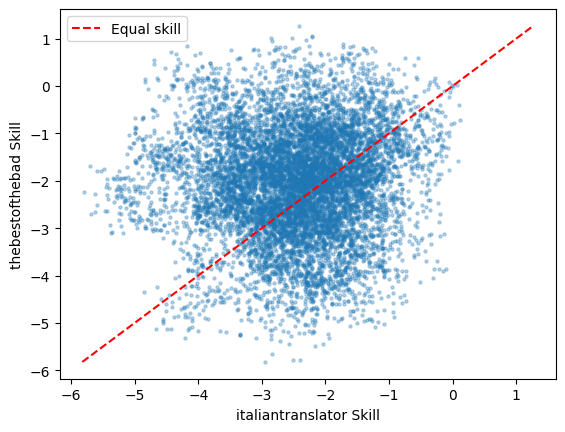

In [69]:
idx_a = np.where(names == "italiantranslator")[0][0]
idx_b = np.where(names == "thebestofthebad")[0][0]

skills_a = all_games_samples[:, idx_a].detach().cpu().numpy()
skills_b = all_games_samples[:, idx_b].detach().cpu().numpy()

lower = min(skills_a.min(), skills_b.min())
upper = max(skills_a.max(), skills_b.max())

plt.scatter(skills_a, skills_b, s=5, alpha=0.3)
plt.plot([lower, upper], [lower, upper], "r--", label="Equal skill")
plt.xlabel("italiantranslator Skill")
plt.ylabel("thebestofthebad Skill")
plt.legend()
plt.show()

### Q 2.4.g [3 points]
Using your samples, find the player with the 14th highest mean skill. Print a Monte Carlo estimate of the probability that the player with the 16th highest mean skill is not worse than `bassboy`, again as estimated from your samples.  Hint: Probabilities of Bernoulli random variables can be written as the expectation that the Bernoulli takes value 1, so you can use simple Monte Carlo.  The final formula will be very simple.

In [71]:
mean_skills = all_games_samples.mean(dim=0)
ranked_ixs = torch.argsort(mean_skills, descending=True)

# Player with the 14th highest mean skill.
idx_14 = ranked_ixs[13].item()
print("14th highest mean skill:", names[idx_14])

# Probability that the 16th-ranked player is not worse than bassboy.
idx_16 = ranked_ixs[15].item()
idx_bassboy = np.where(names == "bassboy")[0][0]

prob = (all_games_samples[:, idx_16] >= all_games_samples[:, idx_bassboy]).float().mean().item()

print("16th highest mean skill:", names[idx_16])
print("P(16th-ranked player is not worse than bassboy):", prob)

14th highest mean skill: gqueen
16th highest mean skill: lzchips
P(16th-ranked player is not worse than bassboy): 0.6581000089645386


### Q 2.4.h [3 points]

For any two players $i$ and $j$, $p(z_i, z_j | \text{all games})$ is always proportional to $p(z_i, z_j , \text{all games})$, as a function of $z_i$ and $z_j$.

In general, are the isocontours of $p(z_i, z_j | \text{all games})$ the same as those of $p(z_i, z_j | \text{games between $i$ and $j$})$?  That is, do the games between other players besides $i$ and $j$ provide information about the skill of players $i$ and $j$?  A simple yes or no suffices.

Hint: One way to answer this is to draw the graphical model for three players, $i$, $j$, and $k$, and the results of games between all three pairs, and then examine conditional independencies.  If you do this, include the graphical models in your assignment.

Your answer here:

No, the isocontours are not generally the same.

Games involving other players provide information about the skills of the opponents of i and j, which can in turn update our beliefs about the skills of i and j.